# 05 · Bowling Line and Length Analysis

Plot where each delivery pitched, sort deliveries into line and length bands, and measure how accurate and how consistent a bowler was.

Needs: numpy, pandas, matplotlib (`pip install -r notebooks/requirements.txt`).

> Running in Google Colab? Run this once in a new cell first (replace the URL with wherever your copy of the project lives), then run the notebook from the top:
> ```python
> !git clone https://github.com/YOUR-ACCOUNT/pitchvision.git   # or upload and unzip the project folder
> %cd pitchvision
> !pip install -q -r notebooks/requirements.txt
> ```

> About the data. The CSV files in `notebooks/data/` are synthetic: generated by `pitchvision/sample_data.py` with a fixed random seed. The players, matches and numbers are invented so the notebook can run straight away. They are not a real team's results. To use your own data, replace the CSV files with files that have the same columns (see `notebooks/data/DATA_DICTIONARY.md`).

In [1]:
# --- Setup: find the project folder so the shared `pitchvision` package can be imported ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pitchvision").exists():        # the notebook is being run from notebooks/
    ROOT = ROOT.parent
if not (ROOT / "pitchvision").exists():
    raise RuntimeError("Cannot find the 'pitchvision' folder. Open this notebook from inside the PitchVision "
                       "project, or see the Google Colab instructions in notebooks/README.md.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "notebooks" / "data"             # sample CSV files (SYNTHETIC data)
EXPORTS = ROOT / "notebooks" / "exports"       # CSV files written by the notebooks
EXPORTS.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, GREEN, RED, YELLOW = "#0D1310", "#1F6B45", "#B3261E", "#F2C230"
print("Project folder:", ROOT)

Project folder: /Users/sahasreddy/Documents/Cricket


## 1. The pitch coordinate system

Every delivery is stored as two numbers.

`x` is how far across the pitch it landed, in metres from the line of middle stump. Positive means the off side. Left-handers are mirrored when the data is entered, so positive is always off.

`y` is how far from the striker's stumps it landed, in metres. The stumps are at 0 and the bowler's stumps at 20.12.

| Length | Pitches (m from the stumps) |
|---|---|
| Yorker | 0 to 2 |
| Full | 2 to 6 |
| Good | 6 to 8 |
| Short | 8 to 10 |
| Bouncer | over 10 |

| Line | x (m) |
|---|---|
| Wide leg | below -0.45 |
| Leg | -0.45 to -0.114 |
| Stumps | within 0.114 of middle |
| Off | 0.114 to 0.45 |
| Wide off | above 0.45 |

These bands are coaching conventions for pace bowling. A coach can change them in `pitchvision/constants.py`.

In [2]:
from pitchvision import pitchmap
from pitchvision.constants import LENGTH_BANDS, LINE_BANDS, PITCH_WIDTH_M, WICKET_HALF_WIDTH_M

def length_by_hand(y):
    """Length band from the distance to the stumps."""
    if y < 2: return "yorker"
    if y < 6: return "full"
    if y < 8: return "good"
    if y < 10: return "short"
    return "bouncer"

for y in [0.5, 1.99, 2.0, 5.9, 6.0, 7.99, 8.0, 9.5, 12.0]:
    assert length_by_hand(y) == pitchmap.classify_length(y)
print("Hand-written bands match pitchvision.pitchmap.classify_length")
print([pitchmap.classify_line(x) for x in (-0.9, -0.2, 0.0, 0.2, 0.6)])

Hand-written bands match pitchvision.pitchmap.classify_length
['wide_leg', 'leg', 'stumps', 'off', 'wide_off']


## 2. Load the deliveries

Each row is one ball from a net session. A few rows have no `x`. Those balls were seen but not located, so they are counted and left out of every calculation.

In [3]:
deliveries = pd.read_csv(DATA / "deliveries.csv", parse_dates=["date"])
print(len(deliveries), "deliveries,", deliveries["x"].isna().sum(), "with no recorded line")
located = deliveries.dropna(subset=["x", "y"]).copy()
located["length"] = located["y"].apply(pitchmap.classify_length)
located["line"] = located["x"].apply(pitchmap.classify_line)
located.head()

768 deliveries, 6 with no recorded line


,player,session,session_no,date,x,y,bowl_type,synthetic,length,line
0,Ethan Brooks,Ethan-S1,1,2025-04-29,-0.262,6.436,spin,True,good,leg
1,Ethan Brooks,Ethan-S1,1,2025-04-29,-0.007,1.010,spin,True,yorker,stumps
2,Ethan Brooks,Ethan-S1,1,2025-04-29,0.667,6.675,spin,True,good,wide_off
3,Ethan Brooks,Ethan-S1,1,2025-04-29,0.496,3.525,spin,True,full,wide_off
4,Ethan Brooks,Ethan-S1,1,2025-04-29,-0.141,6.749,spin,True,good,leg


## 3. A pitch map for one bowler

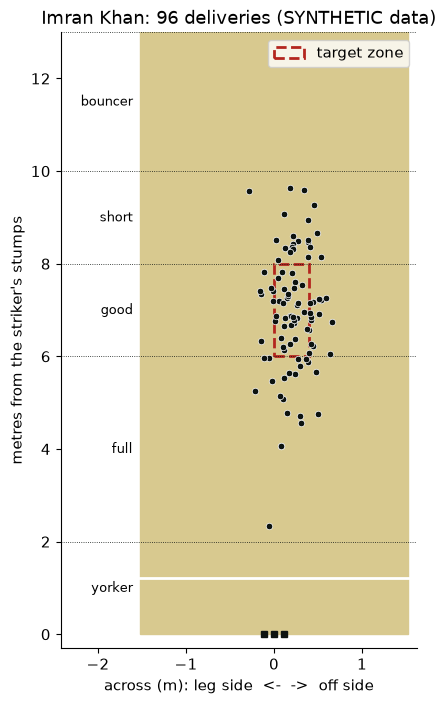

In [4]:
def draw_pitch(ax, y_max=13):
    ax.add_patch(plt.Rectangle((-PITCH_WIDTH_M / 2, 0), PITCH_WIDTH_M, y_max, color="#D8C98F", zorder=0))
    for name, lo, hi in LENGTH_BANDS:
        if lo < y_max:
            ax.axhline(min(hi, y_max), color=INK, lw=0.6, ls=":")
            ax.text(-PITCH_WIDTH_M / 2 - 0.08, (lo + min(hi, y_max)) / 2, name, ha="right", va="center", fontsize=9)
    ax.axhline(1.22, color="white", lw=2)                       # popping crease
    for s in (-WICKET_HALF_WIDTH_M, 0, WICKET_HALF_WIDTH_M):
        ax.plot(s, 0, "s", color=INK, ms=5)
    ax.set_xlim(-PITCH_WIDTH_M / 2 - 0.9, PITCH_WIDTH_M / 2 + 0.1); ax.set_ylim(-0.3, y_max)
    ax.set_xlabel("across (m): leg side  <-  ->  off side"); ax.set_ylabel("metres from the striker's stumps"); ax.grid(False)

bowler = "Imran Khan"
mine = located[located["player"] == bowler]
target = {"x": 0.2, "y": 7.0, "tol_x": 0.2, "tol_y": 1.0}

fig, ax = plt.subplots(figsize=(4.6, 8))
draw_pitch(ax)
ax.add_patch(plt.Rectangle((target["x"] - target["tol_x"], target["y"] - target["tol_y"]), 2 * target["tol_x"], 2 * target["tol_y"],
                           fill=False, ec=RED, lw=2, ls="--", label="target zone"))
ax.scatter(mine["x"], mine["y"], color=INK, s=22, edgecolor="white", linewidth=0.5, zorder=3)
ax.set_title(f"{bowler}: {len(mine)} deliveries (SYNTHETIC data)"); ax.legend(loc="upper right"); plt.show()

## 4. Delivery distribution

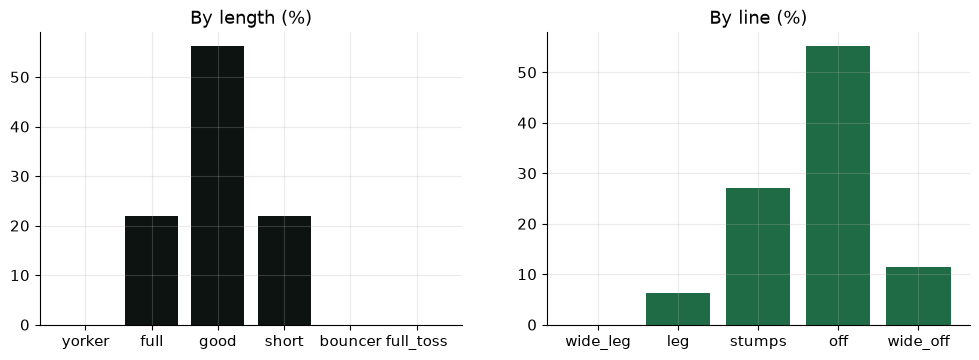

,count,pct
band,,
yorker,0,0.0
full,21,21.9
good,54,56.2
short,21,21.9
bouncer,0,0.0
full_toss,0,0.0


In [5]:
dist = pitchmap.distribution(mine.to_dict("records"))
length_table = pd.DataFrame(dist["length"]).set_index("band")
line_table = pd.DataFrame(dist["line"]).set_index("band")
assert length_table["count"].sum() == len(mine)                 # every located ball is in exactly one band

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(length_table.index, length_table["pct"], color=INK); axes[0].set_title("By length (%)")
axes[1].bar(line_table.index, line_table["pct"], color=GREEN); axes[1].set_title("By line (%)")
plt.show()
length_table.round(1)

## 5. Accuracy and consistency

Accuracy is measured against a target the coach sets: a line, a length, and a tolerance for each.

The hit rate is the share of deliveries inside the target box. The mean error is the average straight-line distance from the target. Bias is the average signed miss, which tells you where the group is centred. Spread is the standard deviation, which tells you how tight the group is.

A bowler can be consistent and still inaccurate: a tight group in the wrong place has a small spread and a large bias. The fix for that is a different aim. A wide spread needs work on repeating the action.

In [6]:
def accuracy_by_hand(df, tx, ty, tol_x, tol_y):
    hits = ((df["x"] - tx).abs() <= tol_x) & ((df["y"] - ty).abs() <= tol_y)
    return {"hit_pct": hits.mean() * 100,
            "mean_error_m": np.hypot(df["x"] - tx, df["y"] - ty).mean(),
            "bias_x": df["x"].mean() - tx, "bias_y": df["y"].mean() - ty,
            "spread_x": df["x"].std(ddof=0), "spread_y": df["y"].std(ddof=0)}

hand = accuracy_by_hand(mine, **{"tx": 0.2, "ty": 7.0, "tol_x": 0.2, "tol_y": 1.0})
app = pitchmap.accuracy(mine.to_dict("records"), 0.2, 7.0, 0.2, 1.0)
for k, v in hand.items():
    assert abs(v - app[k]) < 1e-9, k
print(f"In the target zone: {app['hit_pct']:.0f}% ({app['hits']} of {app['total']})")
print(f"Average miss: {app['mean_error_m']:.2f} m")
print(f"Group centre: {app['bias_x'] * 100:+.0f} cm across, {app['bias_y']:+.2f} m in length, relative to the target")
print(f"Spread: {app['spread_x'] * 100:.0f} cm in line, {app['spread_y']:.2f} m in length")
print(f"Consistency index: {app['consistency_index']:.0f} / 100")

In the target zone: 35% (34 of 96)
Average miss: 1.02 m
Group centre: +2 cm across, -0.06 m in length, relative to the target
Spread: 20 cm in line, 1.30 m in length
Consistency index: 44 / 100


## 6. Heatmap

A heatmap counts deliveries in each cell of a grid laid over the pitch. It shows the pattern better than individual dots once there are many deliveries.

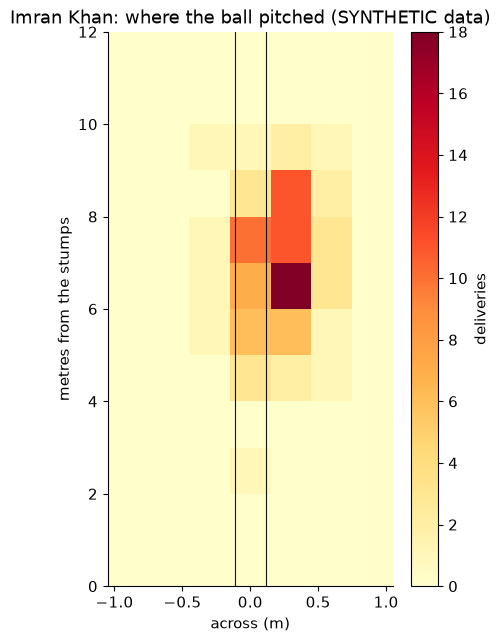

Deliveries outside the grid: 0


In [7]:
heat = pitchmap.heatmap(mine.to_dict("records"))
fig, ax = plt.subplots(figsize=(4.6, 7.2))
im = ax.imshow(heat["counts"], origin="lower", cmap="YlOrRd", aspect="auto",
               extent=[heat["x_edges"][0], heat["x_edges"][-1], heat["y_edges"][0], heat["y_edges"][-1]])
ax.axvline(-WICKET_HALF_WIDTH_M, color=INK, lw=0.8); ax.axvline(WICKET_HALF_WIDTH_M, color=INK, lw=0.8)
ax.set_xlabel("across (m)"); ax.set_ylabel("metres from the stumps"); ax.grid(False)
ax.set_title(f"{bowler}: where the ball pitched (SYNTHETIC data)"); plt.colorbar(im, label="deliveries"); plt.show()
print("Deliveries outside the grid:", heat["outside"])

## 7. Comparing sessions

,date,balls,hit %,mean error (m),line spread (cm),length spread (m)
session,,,,,,
1,2025-04-29,24,45.83,1.06,20.32,1.34
2,2025-05-13,24,29.17,0.95,20.74,1.12
3,2025-05-27,24,20.83,1.11,20.36,1.31
4,2025-06-10,24,45.83,0.97,16.64,1.28


Change from the first to the last session: {'hit_pct': 0.0, 'mean_error_m': -0.08, 'spread_x': -0.04, 'spread_y': -0.06, 'consistency_index': 3.52}


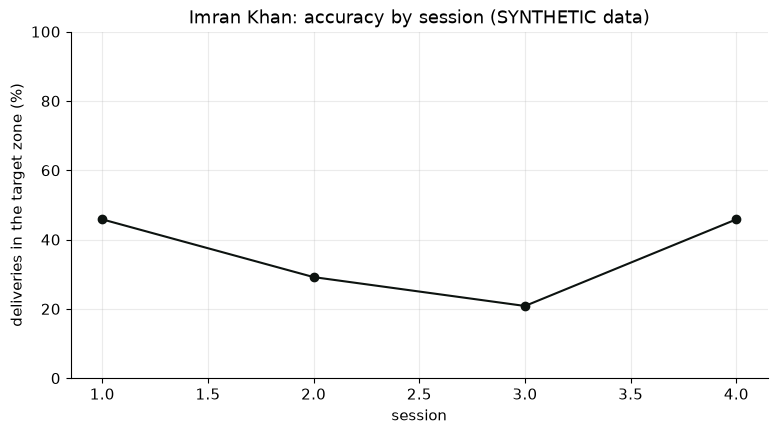

In [8]:
rows = []
for session, g in mine.groupby("session_no"):
    a = pitchmap.accuracy(g.to_dict("records"), 0.2, 7.0)
    rows.append({"session": session, "date": g["date"].iloc[0].date(), "balls": a["total"], "hit %": a["hit_pct"],
                 "mean error (m)": a["mean_error_m"], "line spread (cm)": a["spread_x"] * 100, "length spread (m)": a["spread_y"]})
sessions = pd.DataFrame(rows).set_index("session"); display(sessions.round(2))

first, last = mine[mine["session_no"] == 1], mine[mine["session_no"] == mine["session_no"].max()]
cmp = pitchmap.compare_sessions(first.to_dict("records"), last.to_dict("records"), 0.2, 7.0)
print("Change from the first to the last session:", {k: round(v, 2) for k, v in cmp["change"].items()})

fig, ax = plt.subplots()
ax.plot(sessions.index, sessions["hit %"], marker="o", color=INK)
ax.set_xlabel("session"); ax.set_ylabel("deliveries in the target zone (%)"); ax.set_ylim(0, 100)
ax.set_title(f"{bowler}: accuracy by session (SYNTHETIC data)"); plt.show()

## 8. Every bowler

With only 24 balls a session, a hit rate moves a lot by chance. The last column is a rough 95% range for the hit rate (the normal approximation, 1.96 standard errors either side).

In [9]:
rows = []
for player, g in located.groupby("player"):
    t_y = 5.2 if g["bowl_type"].iloc[0] == "spin" else 7.0       # spinners aim fuller
    a = pitchmap.accuracy(g.to_dict("records"), 0.2, t_y)
    p = a["hit_pct"] / 100
    margin = 1.96 * np.sqrt(p * (1 - p) / a["total"]) * 100
    rows.append({"player": player, "balls": a["total"], "target length": t_y, "hit %": a["hit_pct"], "+/-": margin,
                 "line spread (cm)": a["spread_x"] * 100, "consistency": a["consistency_index"]})
table = pd.DataFrame(rows).set_index("player").sort_values("hit %", ascending=False).round(1)
table.to_csv(EXPORTS / "bowling_accuracy_by_player.csv")
table

,balls,target length,hit %,+/-,line spread (cm),consistency
player,,,,,,
Kabir Rao,96,5.2,42.7,9.9,23.1,43.7
Jack Wood,95,7.0,36.8,9.7,22.9,40.8
Imran Khan,96,7.0,35.4,9.6,19.6,44.3
George Hill,94,5.2,29.8,9.2,25.1,34.1
Farhan Ali,93,7.0,29.0,9.2,19.9,38.4
Liam Shaw,96,7.0,27.1,8.9,22.8,36.2
Milan Das,96,7.0,24.0,8.5,25.1,36.0
Ethan Brooks,96,5.2,15.6,7.3,31.4,31.5


## Summary

### Key findings
- Line and length bands are fixed thresholds on x and y; the hand-written rules match the shared module.
- Accuracy splits into bias (where the group is centred) and spread (how tight it is), and the two call for different practice.
- In the synthetic data the groups tighten across sessions because the generator shrinks the spread by 7% a session.

### Interpretation
Use the hit rate to track one bowler against one target over time. Compare bowlers only when they bowled at the same target, and read the range next to each hit rate before calling one bowler more accurate than another.

### Limitations
- Pitching points are entered by eye or taken from single-camera tracking, so each has an error of several centimetres in line and more in length.
- The bands suit pace bowling at adult pitch length. Junior pitches are shorter and the bands should be scaled.
- A target box rewards landing the ball in an area. It says nothing about pace, movement or what the batter did.
- All figures shown come from synthetic data.

### How this notebook connects to the application
The Bowling Lab's Line and length tab stores each click on the pitch map as an (x, y) delivery and calls `pitchmap.distribution`, `accuracy`, `heatmap` and `compare_sessions` through `GET /api/bowling/sessions/{id}` and `/api/bowling/compare`. The band edges drawn on screen come from `GET /api/pitch/geometry`, which reads the same constants used here.